## Importando Bibliotecas e Carregando os Dados Processados

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

In [2]:
CAMINHO_ATUAL = Path(".").resolve()
if CAMINHO_ATUAL.name == "notebooks":
    RAIZ_PROJETO = CAMINHO_ATUAL.parent
else:
    RAIZ_PROJETO = CAMINHO_ATUAL

PASTA_PROCESSED = RAIZ_PROJETO / "data" / "processed"

df_train = pd.read_csv(PASTA_PROCESSED / "train" / "train_scaled.csv")
df_val   = pd.read_csv(PASTA_PROCESSED / "val" / "val_scaled.csv")
df_test  = pd.read_csv(PASTA_PROCESSED / "test" / "test_scaled.csv")

colunas_features = [c for c in df_train.columns if c.startswith("b1_")]

X_train = df_train[colunas_features].values.astype(np.float32)
X_val   = df_val[colunas_features].values.astype(np.float32)
X_test  = df_test[colunas_features].values.astype(np.float32)

print(f"Treino (Saudável):    {X_train.shape[0]} amostras x {X_train.shape[1]} features")
print(f"Validação (Saudável): {X_val.shape[0]} amostras  x {X_val.shape[1]} features")
print(f"Teste (Falha):        {X_test.shape[0]} amostras x {X_test.shape[1]} features")

Treino (Saudável):    401 amostras x 11 features
Validação (Saudável): 80 amostras  x 11 features
Teste (Falha):        451 amostras x 11 features


## 1. Definindo o Modelo: MLP Autoencoder
O Autoencoder comprime as **11 features** originais até um **espaço latente (gargalo) de 4 números** e tenta reconstruir as 11 features originais na saída.

In [3]:
torch.manual_seed(42)
np.random.seed(42)

class MLPAutoencoder(nn.Module):
    def __init__(self, input_dim=11, latent_dim=4):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.GELU(),
            nn.Linear(32, 16),
            nn.GELU(),
            nn.Linear(16, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.GELU(),
            nn.Linear(16, 32),
            nn.GELU(),
            nn.Linear(32, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon

modelo = MLPAutoencoder(input_dim=X_train.shape[1], latent_dim=4)
print(modelo)

MLPAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=11, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=16, out_features=4, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=16, out_features=32, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=32, out_features=11, bias=True)
  )
)


## 2. Treinamento Não-Supervisionado (Apenas com Dados Saudáveis)

In [4]:
criterio = nn.MSELoss()
otimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-3, weight_decay=1e-4)

loader_treino = DataLoader(TensorDataset(torch.from_numpy(X_train)), batch_size=32, shuffle=True)

historico_treino = []
historico_val = []

epocas = 150
for epoca in range(epocas):
    modelo.train()
    perda_epoca = 0.0
    for (lote,) in loader_treino:
        otimizador.zero_grad()
        reconstruido = modelo(lote)
        loss = criterio(reconstruido, lote)
        loss.backward()
        otimizador.step()
        perda_epoca += loss.item() * len(lote)
    
    historico_treino.append(perda_epoca / len(X_train))
    
    # Avaliando erro de reconstrução na validação saudável
    modelo.eval()
    with torch.no_grad():
        val_recon = modelo(torch.from_numpy(X_val))
        val_loss = criterio(val_recon, torch.from_numpy(X_val)).item()
        historico_val.append(val_loss)

print(f"MSE Final no Treino:    {historico_treino[-1]:.4f}")
print(f"MSE Final na Validação: {historico_val[-1]:.4f}")

MSE Final no Treino:    0.1833
MSE Final na Validação: 0.2347


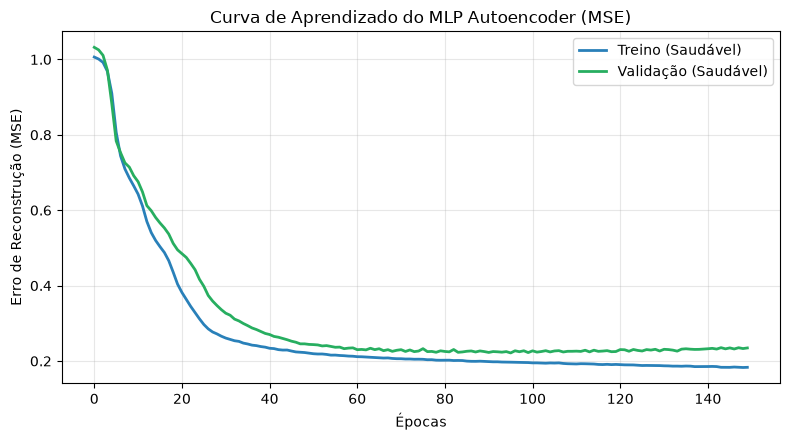

In [5]:
plt.figure(figsize=(8, 4.5))
plt.plot(historico_treino, label="Treino (Saudável)", color="#2980b9", lw=2)
plt.plot(historico_val, label="Validação (Saudável)", color="#27ae60", lw=2)
plt.title("Curva de Aprendizado do MLP Autoencoder (MSE)")
plt.xlabel("Épocas")
plt.ylabel("Erro de Reconstrução (MSE)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Cálculo do Erro de Reconstrução e Definição do Limiar (*Threshold*)

In [6]:
modelo.eval()
with torch.no_grad():
    recon_train = modelo(torch.from_numpy(X_train)).numpy()
    recon_val   = modelo(torch.from_numpy(X_val)).numpy()
    recon_test  = modelo(torch.from_numpy(X_test)).numpy()

# Erro Quadrático Médio (MSE) por amostra (arquivo)
erro_train = np.mean((X_train - recon_train) ** 2, axis=1)
erro_val   = np.mean((X_val - recon_val) ** 2, axis=1)
erro_test  = np.mean((X_test - recon_test) ** 2, axis=1)

# Limiar definido como o Percentil 99 do erro no treino saudável
limiar = np.percentile(erro_train, 99)
print(f"Limiar de Anomalia (Percentil 99 do Treino): {limiar:.4f}")

Limiar de Anomalia (Percentil 99 do Treino): 0.6977


## 4. Avaliação: Curva ROC, Matriz de Confusão e Detecção de Falha (RUL)

In [7]:
# Juntando Validação (Saudável = 0) e Teste (Falha = 1) para calcular as métricas
y_real = np.concatenate([np.zeros(len(erro_val)), np.ones(len(erro_test))])
scores = np.concatenate([erro_val, erro_test])
y_pred = (scores > limiar).astype(int)

df_resultados = pd.DataFrame([{
    "Modelo": "MLP Autoencoder",
    "Accuracy": accuracy_score(y_real, y_pred),
    "Precision": precision_score(y_real, y_pred),
    "Recall (Taxa de Detecção)": recall_score(y_real, y_pred),
    "F1-Score": f1_score(y_real, y_pred),
    "ROC-AUC": roc_auc_score(y_real, scores)
}])
display(df_resultados.round(4))

,Modelo,Accuracy,Precision,Recall (Taxa de Detecção),F1-Score,ROC-AUC
0,MLP Autoencoder,0.9962,0.9978,0.9978,0.9978,0.9983


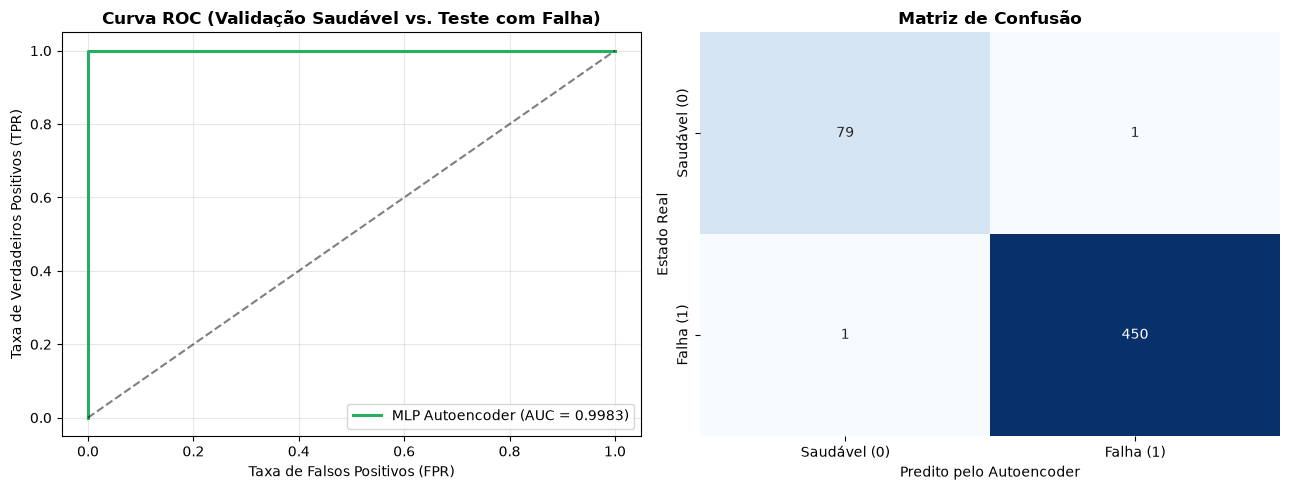

In [8]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

# 1. Curva ROC
fpr, tpr, _ = roc_curve(y_real, scores)
auc_val = roc_auc_score(y_real, scores)
axes[0].plot(fpr, tpr, lw=2.2, color="#27ae60", label=f"MLP Autoencoder (AUC = {auc_val:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Curva ROC (Validação Saudável vs. Teste com Falha)", fontweight="bold")
axes[0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos (TPR)")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# 2. Matriz de Confusão
cm = confusion_matrix(y_real, y_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
    xticklabels=["Saudável (0)", "Falha (1)"],
    yticklabels=["Saudável (0)", "Falha (1)"]
)
axes[1].set_title("Matriz de Confusão", fontweight="bold")
axes[1].set_xlabel("Predito pelo Autoencoder")
axes[1].set_ylabel("Estado Real")

plt.tight_layout()
plt.show()

In [9]:
# Cálculo do 1º Alarme Sustentado (5 arquivos consecutivos acima do limiar) e RUL
acima_limiar = (erro_test > limiar).astype(int)
indices_teste = df_test["idx"].values
janela_sustentada = 5
fim_da_vida_idx = 981

primeiro_alarme_idx = None
for i in range(len(acima_limiar) - janela_sustentada + 1):
    if np.all(acima_limiar[i : i + janela_sustentada] == 1):
        primeiro_alarme_idx = int(indices_teste[i])
        break

rul_arquivos = fim_da_vida_idx - primeiro_alarme_idx
rul_horas = rul_arquivos * 10.0 / 60.0

print(f"1º Alarme Sustentado no Arquivo: {primeiro_alarme_idx}")
print(f"Vida Útil Restante (RUL) no Alarme: {rul_arquivos} arquivos (~{rul_horas:.2f} horas antes do colapso)")

1º Alarme Sustentado no Arquivo: 532
Vida Útil Restante (RUL) no Alarme: 449 arquivos (~74.83 horas antes do colapso)


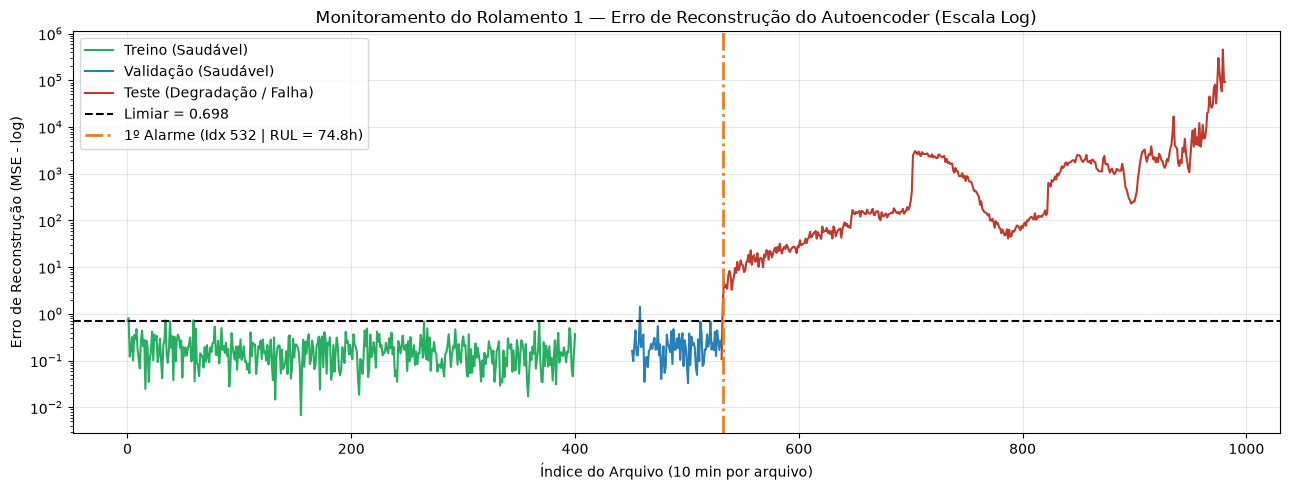

In [10]:
# Plotando a Evolução do Erro de Reconstrução ao longo de toda a vida do Rolamento
plt.figure(figsize=(13, 5))

plt.plot(df_train["idx"], erro_train, color="#27ae60", label="Treino (Saudável)", lw=1.5)
plt.plot(df_val["idx"], erro_val, color="#2980b9", label="Validação (Saudável)", lw=1.5)
plt.plot(df_test["idx"], erro_test, color="#c0392b", label="Teste (Degradação / Falha)", lw=1.5)

plt.axhline(limiar, color="black", linestyle="--", lw=1.5, label=f"Limiar = {limiar:.3f}")
if primeiro_alarme_idx is not None:
    plt.axvline(primeiro_alarme_idx, color="#e67e22", linestyle="-.", lw=2,
                label=f"1º Alarme (Idx {primeiro_alarme_idx} | RUL = {rul_horas:.1f}h)")

plt.yscale("log")
plt.title("Monitoramento do Rolamento 1 — Erro de Reconstrução do Autoencoder (Escala Log)")
plt.xlabel("Índice do Arquivo (10 min por arquivo)")
plt.ylabel("Erro de Reconstrução (MSE - log)")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Total de amostras anômalas detectadas no teste: 450 / 451


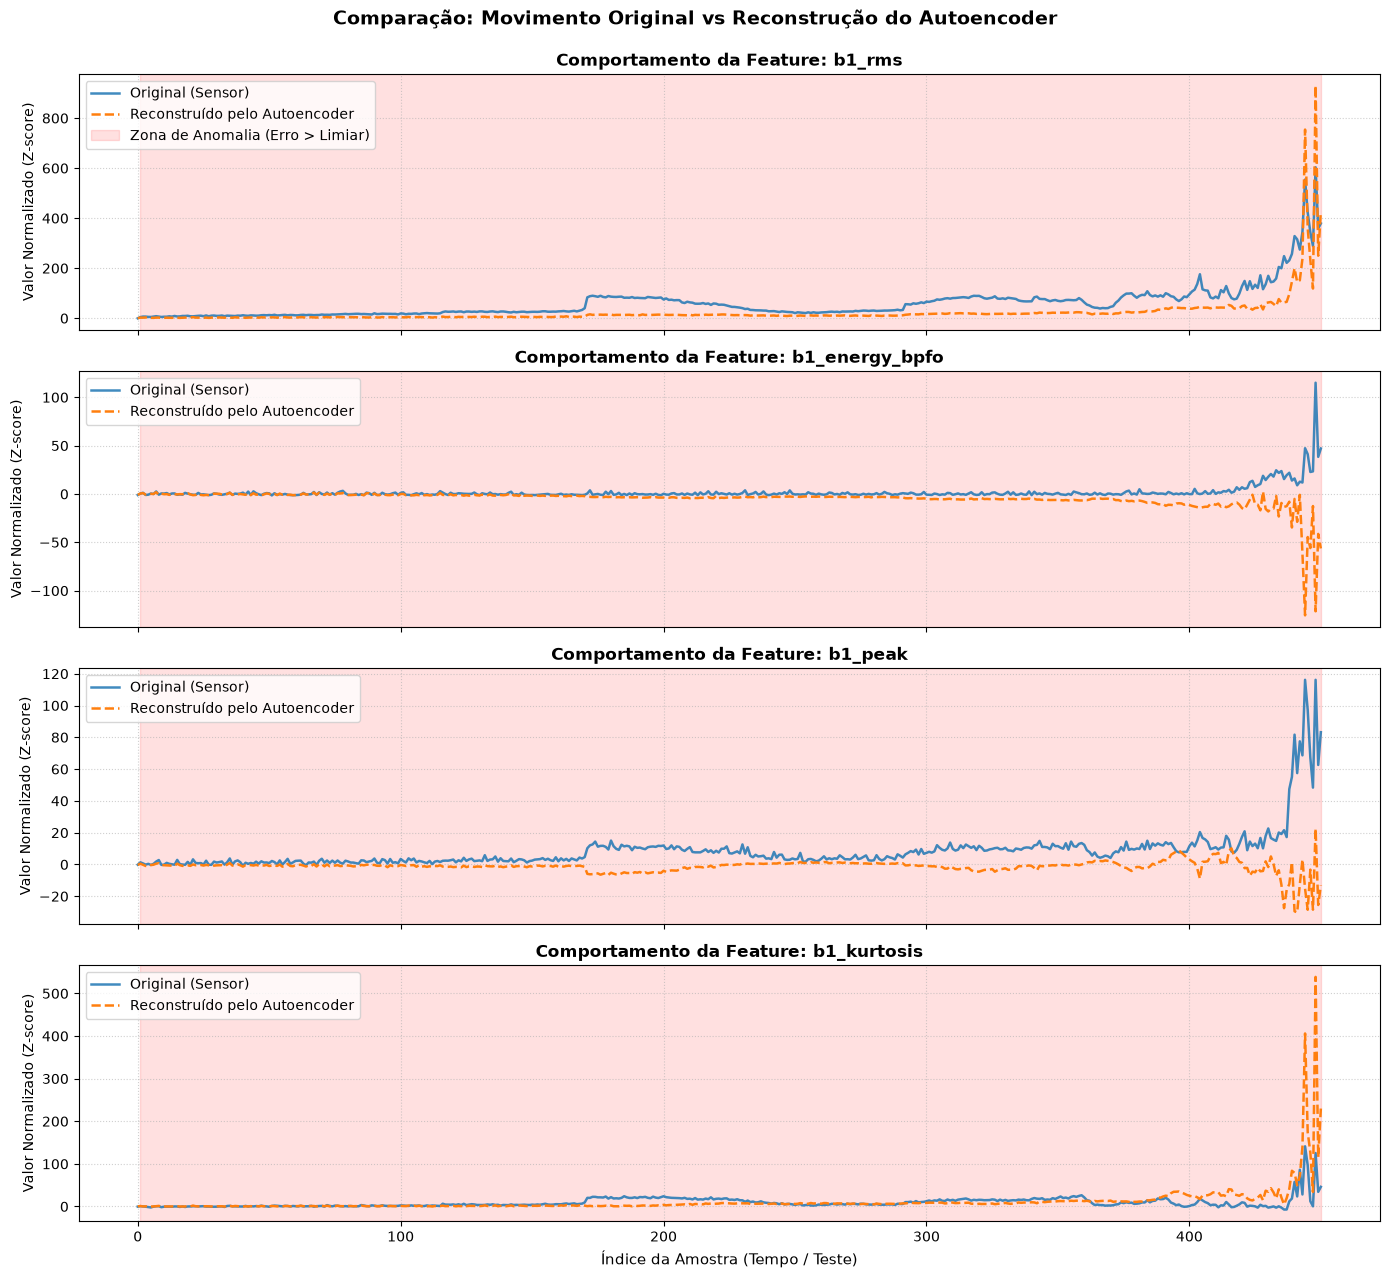

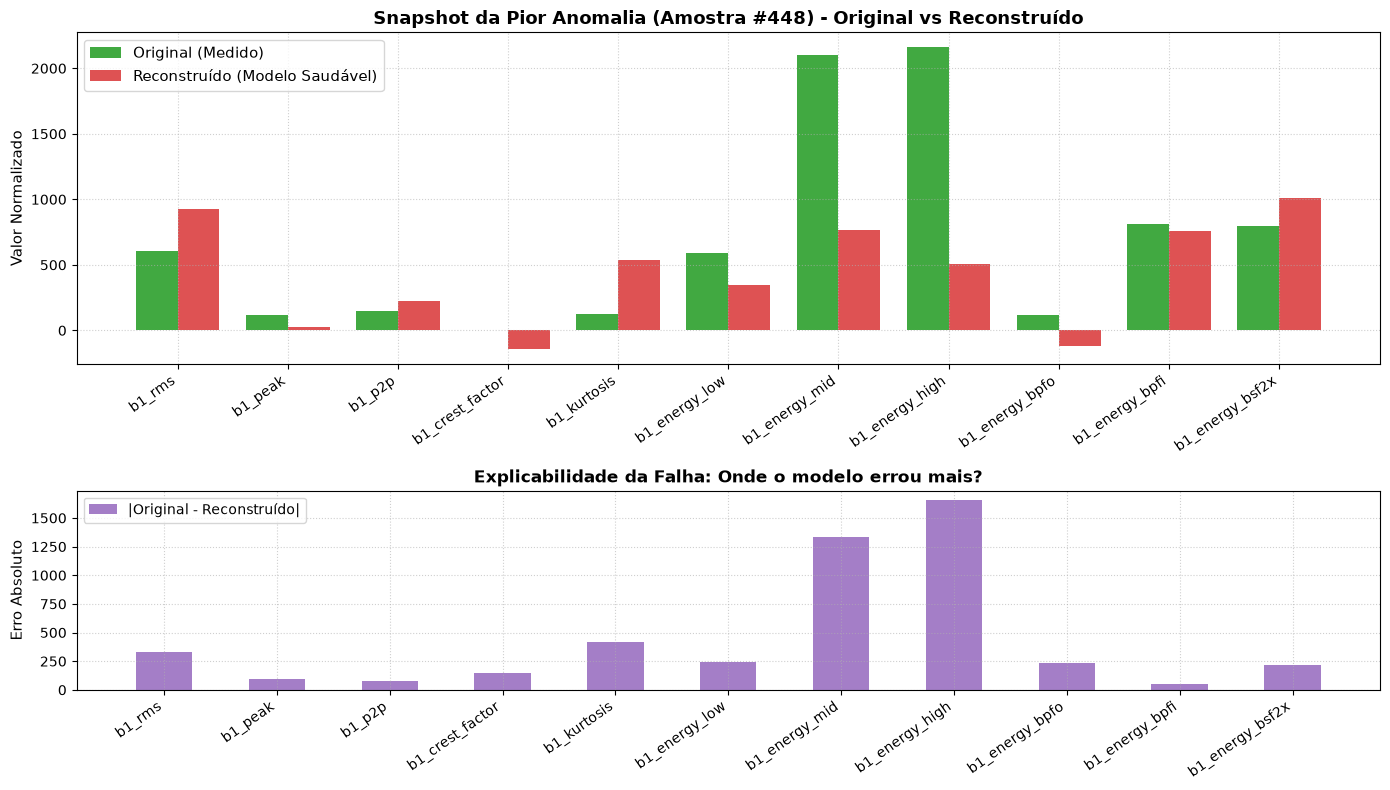

In [13]:
# 1. Garante o modo de avaliação e gera as reconstruções do X_test
modelo.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    recon_test = modelo(X_test_tensor).numpy()

# Erro quadrático ponto a ponto e por feature
erro_features = (X_test - recon_test) ** 2
erro_test_amostras = erro_features.mean(axis=1)

# Identifica anomalias baseado no limiar
indices_anomalias = np.where(erro_test_amostras > limiar)[0]
print(
    f"Total de amostras anômalas detectadas no teste: {len(indices_anomalias)} / {len(X_test)}"
)

# ==============================================================================
# GRÁFICO 1: Trajetória Temporal - Original vs Reconstruído nas Features Críticas
# ==============================================================================
features_destaque = ["b1_rms", "b1_energy_bpfo", "b1_peak", "b1_kurtosis"]
indices_feat = [
    colunas_features.index(f) for f in features_destaque if f in colunas_features
]

fig, axes = plt.subplots(
    len(indices_feat), 1, figsize=(14, 3.2 * len(indices_feat)), sharex=True
)
if len(indices_feat) == 1:
    axes = [axes]

for ax, idx_f in zip(axes, indices_feat):
    nome_feat = colunas_features[idx_f]

    # Sinal Original vs Sinal Reconstruído
    ax.plot(
        X_test[:, idx_f],
        label="Original (Sensor)",
        color="#1f77b4",
        alpha=0.85,
        linewidth=1.8,
    )
    ax.plot(
        recon_test[:, idx_f],
        label="Reconstruído pelo Autoencoder",
        color="#ff7f0e",
        linestyle="--",
        linewidth=1.8,
    )

    # Destaque das regiões com anomalia detectada
    if len(indices_anomalias) > 0:
        ax.axvspan(
            indices_anomalias[0],
            len(X_test) - 1,
            color="red",
            alpha=0.12,
            label="Zona de Anomalia (Erro > Limiar)"
            if idx_f == indices_feat[0]
            else "",
        )

    ax.set_title(
        f"Comportamento da Feature: {nome_feat}",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_ylabel("Valor Normalizado (Z-score)", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper left")

axes[-1].set_xlabel("Índice da Amostra (Tempo / Teste)", fontsize=11)
plt.suptitle(
    "Comparação: Movimento Original vs Reconstrução do Autoencoder",
    fontsize=14,
    fontweight="bold",
    y=0.995,
)
plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICO 2: Raio-X em um Snapshot Específico de Alta Anomalia
# ==============================================================================
# Seleciona o ponto com o pior erro de reconstrução (pico da falha)
idx_pior_anomalia = np.argmax(erro_test_amostras)

orig_amostra = X_test[idx_pior_anomalia]
recon_amostra = recon_test[idx_pior_anomalia]
erro_amostra = np.abs(orig_amostra - recon_amostra)

x_pos = np.arange(len(colunas_features))
largura = 0.38

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(14, 8), gridspec_kw={"height_ratios": [2, 1.2]}
)

# Painel Superior: Barras lado a lado de Original vs Reconstruído
ax1.bar(
    x_pos - largura / 2,
    orig_amostra,
    width=largura,
    label="Original (Medido)",
    color="#2ca02c",
    alpha=0.9,
)
ax1.bar(
    x_pos + largura / 2,
    recon_amostra,
    width=largura,
    label="Reconstruído (Modelo Saudável)",
    color="#d62728",
    alpha=0.8,
)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(colunas_features, rotation=35, ha="right", fontsize=10)
ax1.set_ylabel("Valor Normalizado", fontsize=11)
ax1.set_title(
    f"Snapshot da Pior Anomalia (Amostra #{idx_pior_anomalia}) - Original vs Reconstruído",
    fontsize=13,
    fontweight="bold",
)
ax1.legend(loc="upper left", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6)

# Painel Inferior: Resíduo / Erro Absoluto por Feature (|Original - Reconstruído|)
ax2.bar(
    x_pos,
    erro_amostra,
    color="#9467bd",
    alpha=0.85,
    width=0.5,
    label="|Original - Reconstruído|",
)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(colunas_features, rotation=35, ha="right", fontsize=10)
ax2.set_ylabel("Erro Absoluto", fontsize=11)
ax2.set_title(
    "Explicabilidade da Falha: Onde o modelo errou mais?",
    fontsize=12,
    fontweight="bold",
)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

## 5. Interpretação do Modelo: Contribuição de Cada Variável no Alarme (*Feature Importance*)

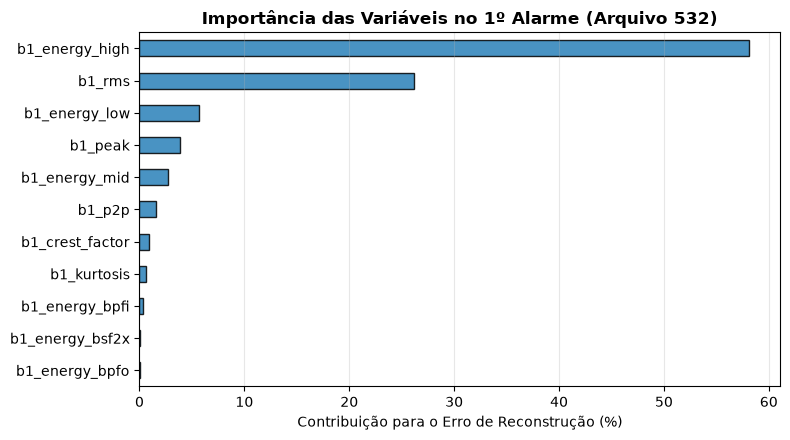

In [11]:
# Qual variável mais aumentou o Erro de Reconstrução no momento do 1º alarme?
pos_alarme = np.where(indices_teste == primeiro_alarme_idx)[0][0]

erro_por_feature = (X_test[pos_alarme] - recon_test[pos_alarme]) ** 2
contribuicao_pct = (erro_por_feature / np.sum(erro_por_feature)) * 100

imp_ae = pd.Series(contribuicao_pct, index=colunas_features).sort_values(ascending=True)

plt.figure(figsize=(8, 4.5))
imp_ae.plot(kind="barh", color="#2980b9", edgecolor="black", alpha=0.85)
plt.title(f"Importância das Variáveis no 1º Alarme (Arquivo {primeiro_alarme_idx})", fontweight="bold")
plt.xlabel("Contribuição para o Erro de Reconstrução (%)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Salvando o Modelo Final e os Scores de Predição

In [12]:
pasta_models = RAIZ_PROJETO / "notebooks" / "models" / "mlp_autoencoder_b1"
pasta_models.mkdir(parents=True, exist_ok=True)

torch.save(modelo.state_dict(), pasta_models / "mlp_autoencoder_b1.pt")

df_predicoes = df_test[["idx", "filename", "timestamp"]].copy()
df_predicoes["erro_reconstrucao"] = erro_test
df_predicoes["anomalia_detectada"] = (erro_test > limiar).astype(int)
df_predicoes.to_csv(pasta_models / "predicoes_teste.csv", index=False)

print("Modelo e predições salvos com sucesso em notebooks/models/mlp_autoencoder_b1/:")
display(df_predicoes.head())

Modelo e predições salvos com sucesso em notebooks/reports/:


,idx,filename,timestamp,erro_reconstrucao,anomalia_detectada
0,531,2004.02.16.03.02.39,2004-02-16 03:02:39,0.107728,0
1,532,2004.02.16.03.12.39,2004-02-16 03:12:39,1.602282,1
2,533,2004.02.16.03.22.39,2004-02-16 03:22:39,4.978455,1
3,534,2004.02.16.03.32.39,2004-02-16 03:32:39,3.702405,1
4,535,2004.02.16.03.42.39,2004-02-16 03:42:39,4.199556,1
